##Data Visualization With Seaborn

#Session 1

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

1.<p>Generate 90 days of daily sales for a fictional kirana store (invent its name) in a notebook named 'kirana_seaborn.ipynb', with columns date (from 2025-01-01), day_type (Weekend for Saturday and Sunday, otherwise Weekday) and sales_inr. Use `np.random.seed(42)` with a normal distribution: mean 12000 and standard deviation 1500 on weekdays, mean 16000 and standard deviation 2000 on weekends, rounded to whole rupees. Save it as 'kirana_sales.csv' and plot sales_inr against date with `sns.lineplot`. Hint: `pd.date_range('2025-01-01', periods=90)` and `dt.dayofweek >= 5` give the dates and the weekend flag.</p>

Shree Krishna Kirana Store


,date,day_type,sales_inr
0,2025-01-01,Weekday,12146
1,2025-01-02,Weekday,13453
2,2025-01-03,Weekday,10947
3,2025-01-04,Weekend,19046
4,2025-01-05,Weekend,15532


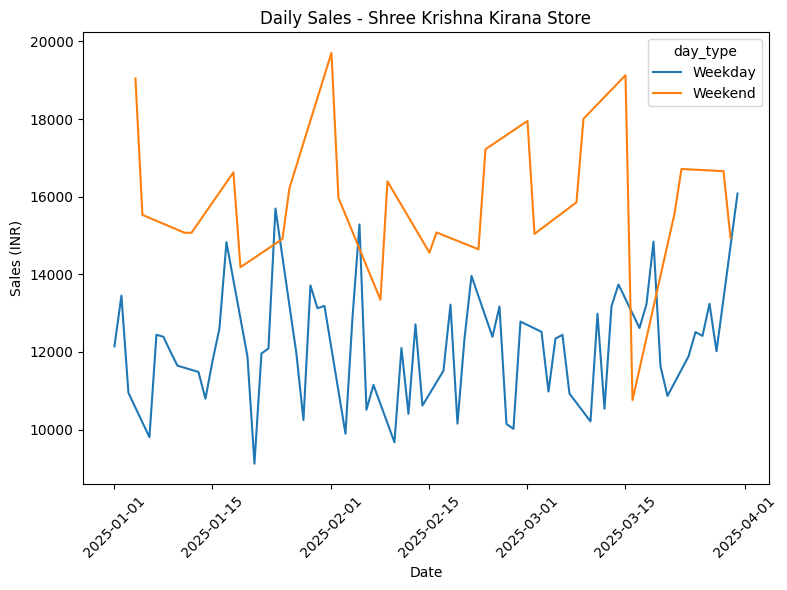

In [2]:
store_name = "Shree Krishna Kirana Store"

# Generate dates
np.random.seed(42)#same random values
dates = pd.date_range('2025-01-01', periods=90)

# Identify Weekday and Weekend
day_type = np.where(dates.dayofweek >= 5, 'Weekend', 'Weekday')  #np.where(condition, True, False) and dayofweek give day number

# Generate sales
sales = np.where(
    day_type == 'Weekend',
    np.random.normal(16000, 2000, 90),
    np.random.normal(12000, 1500, 90)
)

df = pd.DataFrame({
    'date': dates,
    'day_type': day_type,
    'sales_inr': np.round(sales).astype(int)
})

# Save CSV
df.to_csv('kirana_sales.csv', index=False)

# Display data
print(store_name)
display(df.head())

plt.figure(figsize=(8, 6))
sns.lineplot(data=df,x='date',y='sales_inr',hue='day_type')
plt.title(f'Daily Sales - {store_name}')
plt.xlabel('Date')
plt.ylabel('Sales (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2.<p>Draw the same line plot three times side by side in one Matplotlib figure of `figsize=(18, 4)`, once each in the `darkgrid`, `whitegrid` and `ticks` themes, with the theme name as each subplot title. Save the figure as 'kirana_themes.png'. Hint: create each axes inside `with sns.axes_style('darkgrid'):` (for example with `fig.add_subplot(1, 3, 1)`), because a theme applies only to axes created while it is active. Constraint: Use the same data in all three plots.</p>

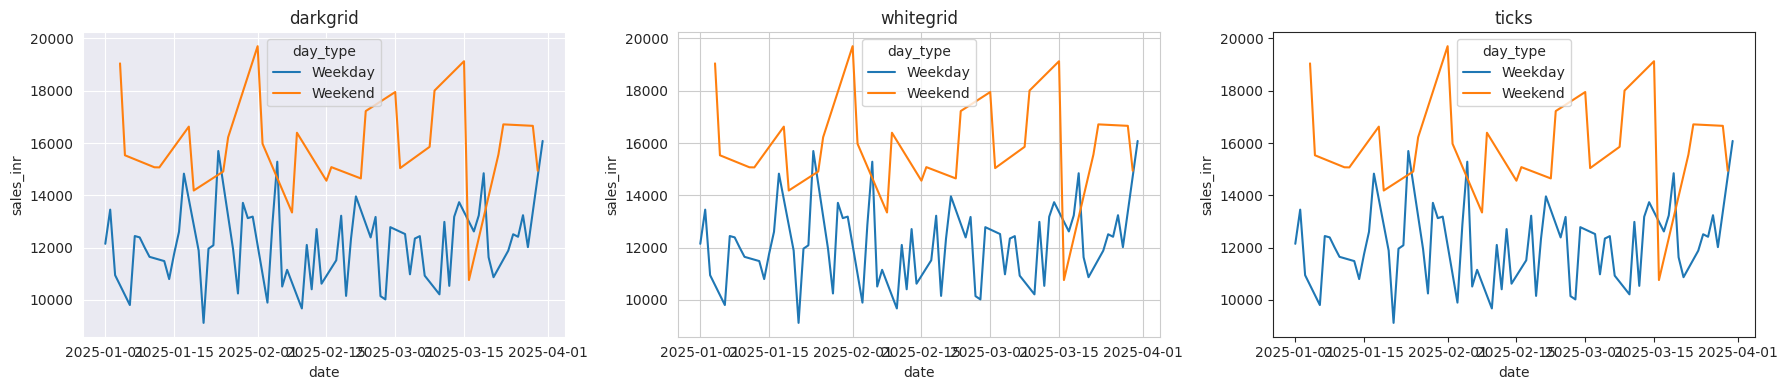

In [3]:
fig = plt.figure(figsize=(18, 4))

# First plot - Darkgrid
with sns.axes_style('darkgrid'):
    ax1 = fig.add_subplot(1, 3, 1)
    sns.lineplot(data=df, x='date', y='sales_inr', hue='day_type', ax=ax1)
    ax1.set_title('darkgrid')

# Second plot - Whitegrid
with sns.axes_style('whitegrid'):
    ax2 = fig.add_subplot(1, 3, 2)
    sns.lineplot(data=df, x='date', y='sales_inr', hue='day_type', ax=ax2)
    ax2.set_title('whitegrid')

# Third plot - Ticks
with sns.axes_style('ticks'):
    ax3 = fig.add_subplot(1, 3, 3)
    sns.lineplot(data=df, x='date', y='sales_inr', hue='day_type', ax=ax3)
    ax3.set_title('ticks')

plt.tight_layout()
plt.savefig('kirana_themes.png')
plt.show()

3.<p>Plot the distribution of sales_inr twice with `bins=15` and `hue='day_type'`: once with the axes-level `sns.histplot` drawn on an axes from `plt.subplots()`, and once with the figure-level `sns.displot`. Print the type each call returns, and save the charts as 'kirana_axes_level.png' and 'kirana_figure_level.png'. Hint: `displot` returns a FacetGrid, which has its own `savefig()` method.</p>

<class 'matplotlib.axes._axes.Axes'>


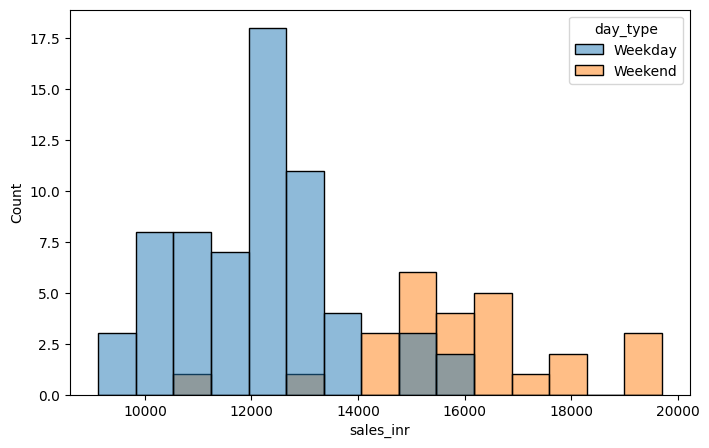

<class 'seaborn.axisgrid.FacetGrid'>


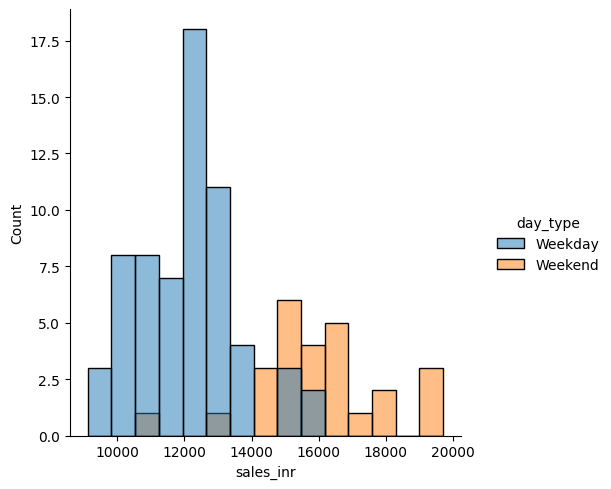

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

ax_return = sns.histplot(data=df,x='sales_inr',bins=15,hue='day_type',ax=ax)
print(type(ax_return))
fig.savefig('kirana_axes_level.png')
plt.show()

# 2. Figure-level plot
g = sns.displot(data=df,x='sales_inr',bins=15,hue='day_type')
print(type(g))
g.savefig('kirana_figure_level.png')
plt.show()

4..<p>Finish the notebook with one report chart in the `ticks` theme: a line plot of sales_inr by date with a title, rupee axis label, date labels rotated 45 degrees and a dashed `plt.axhline` at the overall mean sales. Save it as 'kirana_sales_report.png' with `dpi=150`, then run Restart & Run All and submit the notebook plus the PNG files.</p>

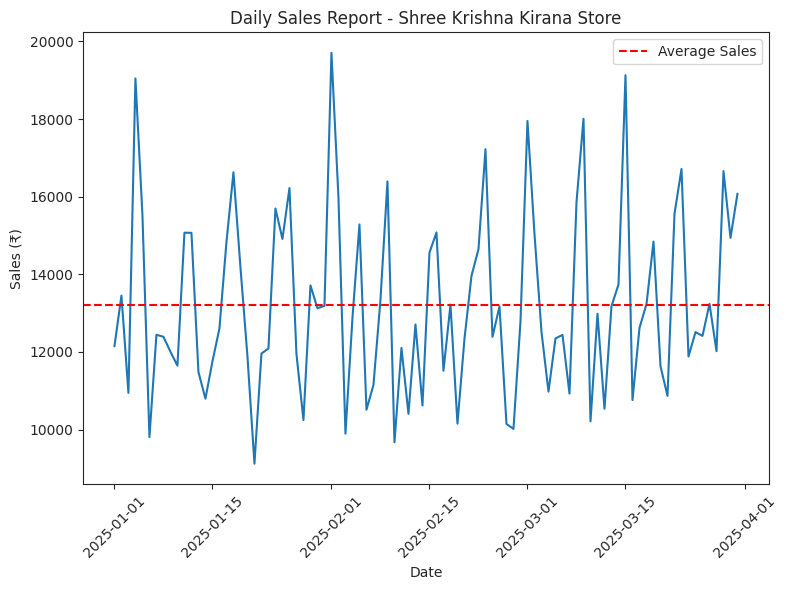

In [5]:
plt.figure(figsize=(8, 6))

with sns.axes_style('ticks'):

    sns.lineplot(data=df,x='date',y='sales_inr')
    plt.title('Daily Sales Report - Shree Krishna Kirana Store')
    plt.xlabel('Date')
    plt.ylabel('Sales (₹)')
    plt.xticks(rotation=45)

    mean_sales = df['sales_inr'].mean()

    plt.axhline(mean_sales,color='red',linestyle='--',label='Average Sales')
    plt.legend()
    plt.tight_layout()
    plt.savefig('kirana_sales_report.png', dpi=150)
    plt.show()